# Site analysis for Hydrosat (VanZyl): what imagery exists at the requested sites

Hydrosat VanZyl products at the sites in the HydroSat site request (or every Optical and Thermal site, with `SITE_REQUEST = None`), searched in two catalogs:

- **CSDA STAC**: the `hydrosat` collection, what NASA CSDA holds and what can be downloaded with Earthdata Login.
- **Hydrosat API**: Hydrosat's own STAC (`hydrosat` provider), the daytime L1B and L2 collections, which carry cloud cover. L1A and the nighttime collections have none, so they are not searched. One acquisition is one `hydrosat:scene_id` across its levels: to order L1A, use the `acquisition_id` of a scene found here.

`res.gdf` says where each row came from, and the download at the end takes the CSDA STAC rows only:

| Column | Meaning |
|---|---|
| `source_stac` | the catalog that returned this row: CSDA STAC or Hydrosat API |
| `available_from` | where this product exists: CSDA STAC and Hydrosat API, CSDA STAC only, or Hydrosat API only |
| `in_csda` | True if CSDA holds this product (matched on the item id, so each processing level counts on its own) |

| Step | Output |
|---|---|
| 1. Catalog overview | first and last acquisition and timeline per collection (catalog-wide) |
| 2. Search | one table with common columns and all vendor properties, and availability by catalog |
| 3. What and where | counts per site and catalog, monthly heatmaps |
| 4. Variation | cloud and geometry distributions, skyplots |
| 5. Download setup | what would be downloaded from CSDA STAC; runs only with `DO_DOWNLOAD = True` |

Library: `lib/multistac.py`, `lib/multistac_plots.py`, `lib/multistac_download.py`.


In [1]:
import sys
sys.path.append('/home/pmontesa/code/csda_summaries/lib')

import importlib
import pandas as pd
import matplotlib.pyplot as plt
import multistac, multistac_plots, multistac_download, site_request
for m in (multistac, multistac_plots, multistac_download, site_request):
    importlib.reload(m)

pd.set_option('display.max_columns', 40)
pd.set_option('display.width', 200)

## Parameters

In [2]:
# Sites: the 'API search' tab of the HydroSat site request, as names in the sites file. A copy of the workbook on ADAPT,
# or a SharePoint link with SHAREPOINT_CLIENT_ID. None = all Optical and Thermal sites instead.
SITE_REQUEST = '/home/pmontesa/code/csda_summaries/sites/OR2 Thermal HydroSat Site Request Draft.xlsx'
SITE_REQUEST_SHEET = 'API search'
SITE_REQUEST_COLUMN = None      # None = the first column headed Site Name, Site or Name
SITE_REQUEST_HEADER_ROW = 0     # 0 = headers in the first row of the sheet
SHAREPOINT_CLIENT_ID = None     # an app registered in the NASA tenant, with delegated Files.Read.All
# Workbook names spelled differently in the sites file, checked against the workbook's coordinates
SITE_REQUEST_ALIASES = {'San Francisco': 'CA_SanFrancisco_1_B23', 'Lake Pontchartrain': 'Lake Pontchartrain Causeway'}

SITES = '/home/pmontesa/code/csda_summaries/sites/eval_sites_aoi.geojson'
SITE_NAME_FIELD = 'Site Name'
SITE_NAMES = None #['San Francisco', 'Railroad Valley','Belo Horizonte']   # None = all sites in the file
# {field: value} on the sites file; str = contains (case-insensitive), list = exact values, callable = takes the column.
# Only without SITE_REQUEST: a filter would drop requested sites outside these domains.
SITE_FILTERS = None if SITE_REQUEST else {'Remote Sensing Domain': lambda s: s.str.contains('Optical|Thermal', case=False, na=False)}

START, END = '2020-01-01', '2026-12-31'   # VanZyl products start 2025-02-21; earlier years confirm there is nothing before
MONTHS = None              # e.g. [6, 7, 8]
CLOUD_COVER_MAX = 0     # percent; None = every product, to see all that is available

CSDA_INCLUDE = ['hydrosat']           # [] = do not search CSDA at all
CSDA_EXCLUDE = []
EXTRA_PROVIDERS = {
    # Hydrosat API: L1B and L2 have cloud cover. A scene's L1A shares its hydrosat:scene_id, so what is found here holds for L1A
    'hydrosat': ['vz-l1b', 'vz-l2'],
}

CACHE_DIR = None   # no cache: CSDA adds Hydrosat data over time, and a cached empty answer would hide it
OUT_DIR = '/explore/nobackup/people/pmontesa/multistac/site_analysis'

# Download (section 5): nothing is downloaded unless DO_DOWNLOAD = True
DO_DOWNLOAD = False
DOWNLOAD_DIR = '/explore/nobackup/projects/CSDA_eval/Data/Hydrosat'
DOWNLOAD_ASSETS = None   # None = every asset of the CSDA STAC items; or a list from the asset table in section 5


In [3]:
if SITE_REQUEST:
    request = site_request.read_table(SITE_REQUEST, SITE_REQUEST_SHEET, header=SITE_REQUEST_HEADER_ROW, client_id=SHAREPOINT_CLIENT_ID)
    requested = [SITE_REQUEST_ALIASES.get(n, n) for n in site_request.site_names(request, SITE_REQUEST_COLUMN)]
    SITE_NAMES, not_found = site_request.match_names(requested, multistac.load_sites(SITES, site_name_field=SITE_NAME_FIELD).site_name)
    print(f'{len(requested)} sites requested, {len(SITE_NAMES)} found in the sites file')
    if len(not_found):
        print('NOT SEARCHED, not in the sites file:')
        display(not_found)
sites = multistac.load_sites(SITES, site_name_field=SITE_NAME_FIELD, filters=SITE_FILTERS)
if SITE_NAMES:
    sites = sites[sites.site_name.isin(SITE_NAMES)]
print(len(sites), 'sites')
#sites.explore(tooltip='site_name') if len(sites) < 300 else sites.plot()


29 sites requested, 29 found in the sites file
29 sites


In [4]:
# CSDA STAC collections: only CSDA_INCLUDE (if set), minus CSDA_EXCLUDE
csda_collections = multistac.collections('csda')
CSDA_IDS = [c for c in csda_collections['id']
            if (CSDA_INCLUDE is None or c in CSDA_INCLUDE) and c not in CSDA_EXCLUDE]
missing = set(CSDA_INCLUDE or []) - set(csda_collections['id'])
if missing:
    print('Not in CSDA STAC (check spelling):', sorted(missing))
print(f'{len(CSDA_IDS)} of {len(csda_collections)} CSDA STAC collections:', ', '.join(CSDA_IDS))

PROVIDERS = {'csda': CSDA_IDS, **EXTRA_PROVIDERS}
providers = multistac.list_providers()
providers[providers.provider.isin(PROVIDERS)][['provider', 'display_name', 'api', 'enabled']]

1 of 27 CSDA STAC collections: hydrosat


,provider,display_name,api,enabled
0,csda,CSDA STAC,stac,True
3,hydrosat,Hydrosat,stac,True


## 1. Catalog overview
Catalog-wide (not just your sites). Collections whose catalog reports no counts show their date range as a band.

No catalog counts from this API (use res.by_month()): csda/hydrosat


,provider,collection,title,first,last,total,dates_from,in_window
0,csda,hydrosat,Hydrosat,2025-09-29,2025-09-29,n/a,items,True
1,hydrosat,vz-l1b,VanZyl Level-1B Combined Thermal & VNIR Data,2025-02-21,2026-11-09,"161,716",items,True
2,hydrosat,vz-l2,VanZyl Level-2 Surface Temperature & Surface R...,2025-02-21,2026-11-09,"161,710",items,True


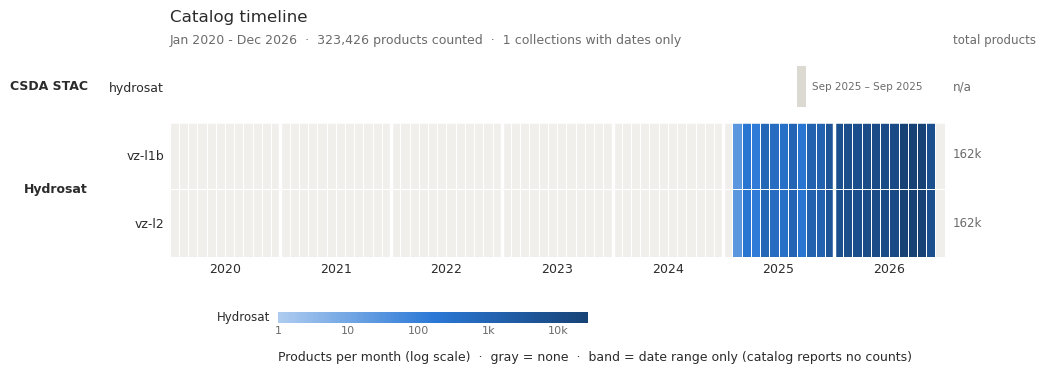

In [5]:
catalog_overview = multistac.overview(PROVIDERS, START, END)
catalog_months = multistac.overview_by_month(PROVIDERS, START, END)
multistac_plots.plot_month_heatmap(catalog_months, spans=catalog_overview, color_by='provider',
                                   start=START[:7], end=END[:7], title='Catalog timeline');
catalog_overview

## 2. Search the sites

In [6]:
%%time
res = multistac.search(sites, START, END, PROVIDERS, months=MONTHS,
                       cloud_cover_max=CLOUD_COVER_MAX, cache_dir=CACHE_DIR)
print(res)
res.log[res.log.status == 'failed']


searches: 100%|██████████| 87/87 [00:06<00:00, 12.97it/s]


SearchResult(218 rows, 188 unique items, 0 failed tasks)
CPU times: user 15 s, sys: 345 ms, total: 15.3 s
Wall time: 21 s


,provider,collection,site_name,interval,status,count,matched,server_filters,error,seconds


In [7]:
res.summary()

,provider,collection,processing_level,rows,products,acquisitions,sites
0,hydrosat,vz-l1b,L1B,109,94,94,24
1,hydrosat,vz-l2,L2,109,94,94,24


In [8]:
# Which catalog each row came from, and where each product exists. Item ids are the same in both catalogs.
SOURCE = {'csda': 'CSDA STAC', 'hydrosat': 'Hydrosat API'}
ids = {p: set(res.gdf.loc[res.gdf.provider == p, 'id']) for p in SOURCE}
both = ids['csda'] & ids['hydrosat']
res.gdf['source_stac'] = res.gdf.provider.map(SOURCE)
res.gdf['available_from'] = [('CSDA STAC and Hydrosat API' if i in both else f'{SOURCE[p]} only')
                             for i, p in zip(res.gdf.id, res.gdf.provider)]
print(f"Products: {len(ids['csda'])} at CSDA STAC, {len(ids['hydrosat'])} at the Hydrosat API, {len(both)} in both")

products = res.gdf.drop_duplicates('id')
display(products.groupby(['available_from', 'processing_level'], dropna=False).agg(
    products=('id', 'size'), acquisitions=('acquisition_id', 'nunique')))
res.gdf.groupby('source_stac').agg(products=('id', 'nunique'), acquisitions=('acquisition_id', 'nunique'), sites=('site_name', 'nunique'),
                                   first=('datetime', 'min'), last=('datetime', 'max'))


Products: 0 at CSDA STAC, 188 at the Hydrosat API, 0 in both


products  acquisitions
available_from    processing_level                        
Hydrosat API only L1B                     94            94
                  L2                      94            94

,products,acquisitions,sites,first,last
source_stac,,,,,
Hydrosat API,188,94,24,2025-05-07 18:42:03.013234+00:00,2026-11-07 21:40:28.770328+00:00


In [9]:
# The result, with source_stac, available_from and in_csda (.gpkg, .csv, items and log)
res.save(f"{OUT_DIR}/hydrosat_{'site_request' if SITE_REQUEST else 'optical_thermal_sites'}")


[PosixPath('/explore/nobackup/people/pmontesa/multistac/site_analysis/hydrosat_site_request.gpkg'),
 PosixPath('/explore/nobackup/people/pmontesa/multistac/site_analysis/hydrosat_site_request.csv'),
 PosixPath('/explore/nobackup/people/pmontesa/multistac/site_analysis/hydrosat_site_request_items.geojson'),
 PosixPath('/explore/nobackup/people/pmontesa/multistac/site_analysis/hydrosat_site_request_log.csv')]

## 3. What do we have, and where?

**These counts are products, not acquisitions.** Each row of `res.gdf` is one catalog item, i.e. one *product*, at one site. One VanZyl acquisition is delivered at several processing levels (L1A, L1B and L2), so it has several products, and a scene that falls on two nearby sites has a row for each.

`acquisition_id` (`hydrosat:scene_id`) groups the products of one scene, in both catalogs. Count `acquisition_id.nunique()` to answer "how many times was this site imaged?", and `id.nunique()` for "how many products are there?". The table below shows both.

**The plots take `count='products'` or `count='acquisitions'`**, and every title, axis and colorbar says which one is counted.


In [10]:
print(res.gdf.columns.to_list())

['provider', 'affiliation', 'constellation', 'sensor', 'collection', 'id', 'datetime', 'site_name', 'site_group', 'cloud_cover', 'processing_level', 'product_type', 'spectral_mode', 'acquisition_id', 'platform', 'instrument', 'gsd', 'off_nadir', 'incidence_angle', 'view_azimuth', 'sun_elevation', 'sun_azimuth', 'sat_azimuth', 'sat_elevation', 'sat_elevation_source', 'vendor_item_id', 'in_csda', 'stac_self_href', 'created', 'updated', 'version', 'proj:code', 'instruments', 'end_datetime', 'view:azimuth', 'proj:centroid', 'eo:cloud_cover', 'start_datetime', 'view:off_nadir', 'sat:orbit_state', 'processing:level', 'view:sun_azimuth', 'hydrosat:scene_id', 'hydrosat:strip_id', 'hydrosat:day_night', 'processing:lineage', 'view:sun_elevation', 'processing:software', 'hydrosat:quality_log', 'hydrosat:geolocation_CE90_meters', 'sat:platform_international_designator', 'hydrosat:access_level', 'asset_NIR_href', 'asset_RED_href', 'asset_BLUE_href', 'asset_GREEN_href', 'asset_LWIR1_href', 'asset_LW

In [11]:
# Products vs acquisitions per constellation, and the product mix (spectral_mode x processing level)
gdf = res.gdf.drop_duplicates(['provider', 'id'])

counts = gdf.groupby(['affiliation', 'constellation']).agg(products=('id', 'size'), acquisitions=('acquisition_id', 'nunique'),
                                                        sites=('site_name', 'nunique'))
counts['products_per_acquisition'] = (counts.products / counts.acquisitions).round(2)
display(counts.sort_values('products', ascending=False))
gdf.groupby(['constellation', 'spectral_mode', 'processing_level'], dropna=False).size().unstack('processing_level', fill_value=0)


,,products,acquisitions,sites,products_per_acquisition
affiliation,constellation,,,,
Hydrosat,VanZyl,188,94,22,2.0


,processing_level,L1B,L2
constellation,spectral_mode,,
VanZyl,ms+tir,94,94


In [12]:
gdf.tail()

,provider,affiliation,constellation,sensor,collection,id,datetime,site_name,site_group,cloud_cover,processing_level,product_type,spectral_mode,acquisition_id,platform,instrument,gsd,off_nadir,incidence_angle,view_azimuth,...,asset_PREVIEW_LWIR_href,asset_THUMBNAIL_LWIR_href,asset_quality_assurance_href,description,asset_LST_href,asset_NIR_SR_href,asset_RED_SR_href,asset_BLUE_SR_href,asset_GREEN_SR_href,asset_LWIR1_EMIS_href,asset_LWIR2_EMIS_href,asset_PREVIEW_LST_href,asset_REDEDGE1_SR_href,asset_REDEDGE2_SR_href,asset_REDEDGE3_SR_href,asset_THUMBNAIL_LST_href,asset_LST_UNCERTAINTY_href,geometry,source_stac,available_from
213,hydrosat,Hydrosat,VanZyl,VZ02,vz-l2,VZ02_L2_20260913_125448,2026-09-13 12:54:48.213019+00:00,Venice,Venice,0,L2,None,ms+tir,VZ02_20260913_125448,vanzyl-02,None,NaN,0.571,NaN,NaN,...,NaN,NaN,,NaN,,,,,,,,,,,,https://assets.hydrosat.com/vz-l2/2026/9/13/VZ...,,"POLYGON ((11.70179 45.52151, 11.47804 44.85023...",Hydrosat API,Hydrosat API only
214,hydrosat,Hydrosat,VanZyl,VZ02,vz-l1b,VZ02_L1b_20260914_125209,2026-09-14 12:52:09.416019+00:00,Venice,Venice,0,L1B,None,ms+tir,VZ02_20260914_125209,vanzyl-02,None,NaN,0.478,NaN,NaN,...,,https://assets.hydrosat.com/vz-l1b/2026/9/14/V...,,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"POLYGON ((12.37559 45.46683, 12.15253 44.79445...",Hydrosat API,Hydrosat API only
215,hydrosat,Hydrosat,VanZyl,VZ02,vz-l2,VZ02_L2_20260914_125209,2026-09-14 12:52:09.416019+00:00,Venice,Venice,0,L2,None,ms+tir,VZ02_20260914_125209,vanzyl-02,None,NaN,0.478,NaN,NaN,...,NaN,NaN,,NaN,,,,,,,,,,,,https://assets.hydrosat.com/vz-l2/2026/9/14/VZ...,,"POLYGON ((12.37559 45.46683, 12.15253 44.79445...",Hydrosat API,Hydrosat API only
216,hydrosat,Hydrosat,VanZyl,VZ01,vz-l1b,VZ01_L1b_20260902_172709,2026-09-02 17:27:09.434041+00:00,WLEF,WLEF,0,L1B,None,ms+tir,VZ01_20260902_172709,vanzyl-01,None,NaN,0.003,NaN,NaN,...,,https://assets.hydrosat.com/vz-l1b/2026/9/2/VZ...,,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"POLYGON ((-90.56827 46.59123, -90.76937 45.982...",Hydrosat API,Hydrosat API only
217,hydrosat,Hydrosat,VanZyl,VZ01,vz-l2,VZ01_L2_20260902_172709,2026-09-02 17:27:09.434041+00:00,WLEF,WLEF,0,L2,None,ms+tir,VZ01_20260902_172709,vanzyl-01,None,NaN,0.003,NaN,NaN,...,NaN,NaN,,NaN,,,,,,,,,,,,https://assets.hydrosat.com/vz-l2/2026/9/2/VZ0...,,"POLYGON ((-90.56827 46.59123, -90.76937 45.982...",Hydrosat API,Hydrosat API only


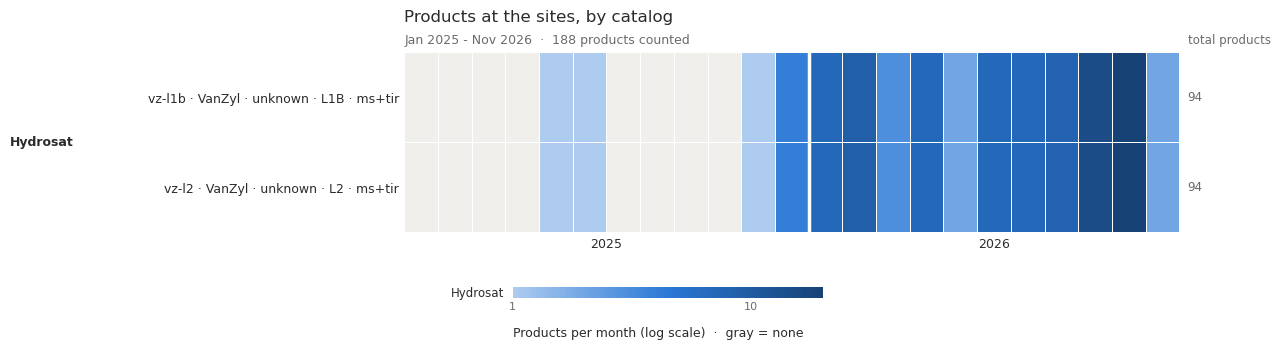

In [13]:
multistac_plots.plot_month_heatmap(res.by_month(['provider', 'collection','constellation','product_type','processing_level','spectral_mode'], count='products'), color_by='provider',
                                   title='Products at the sites, by catalog');

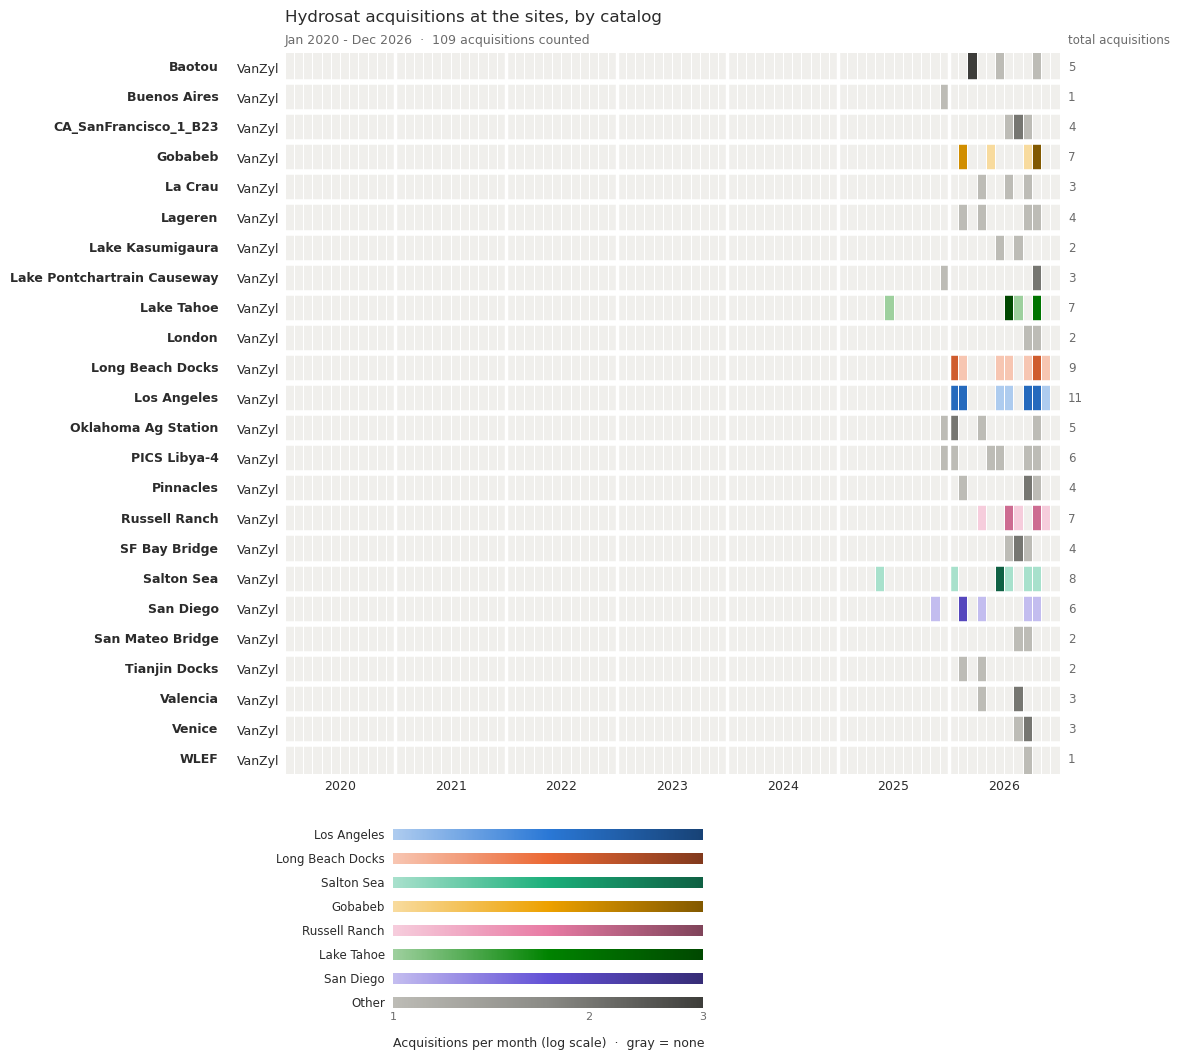

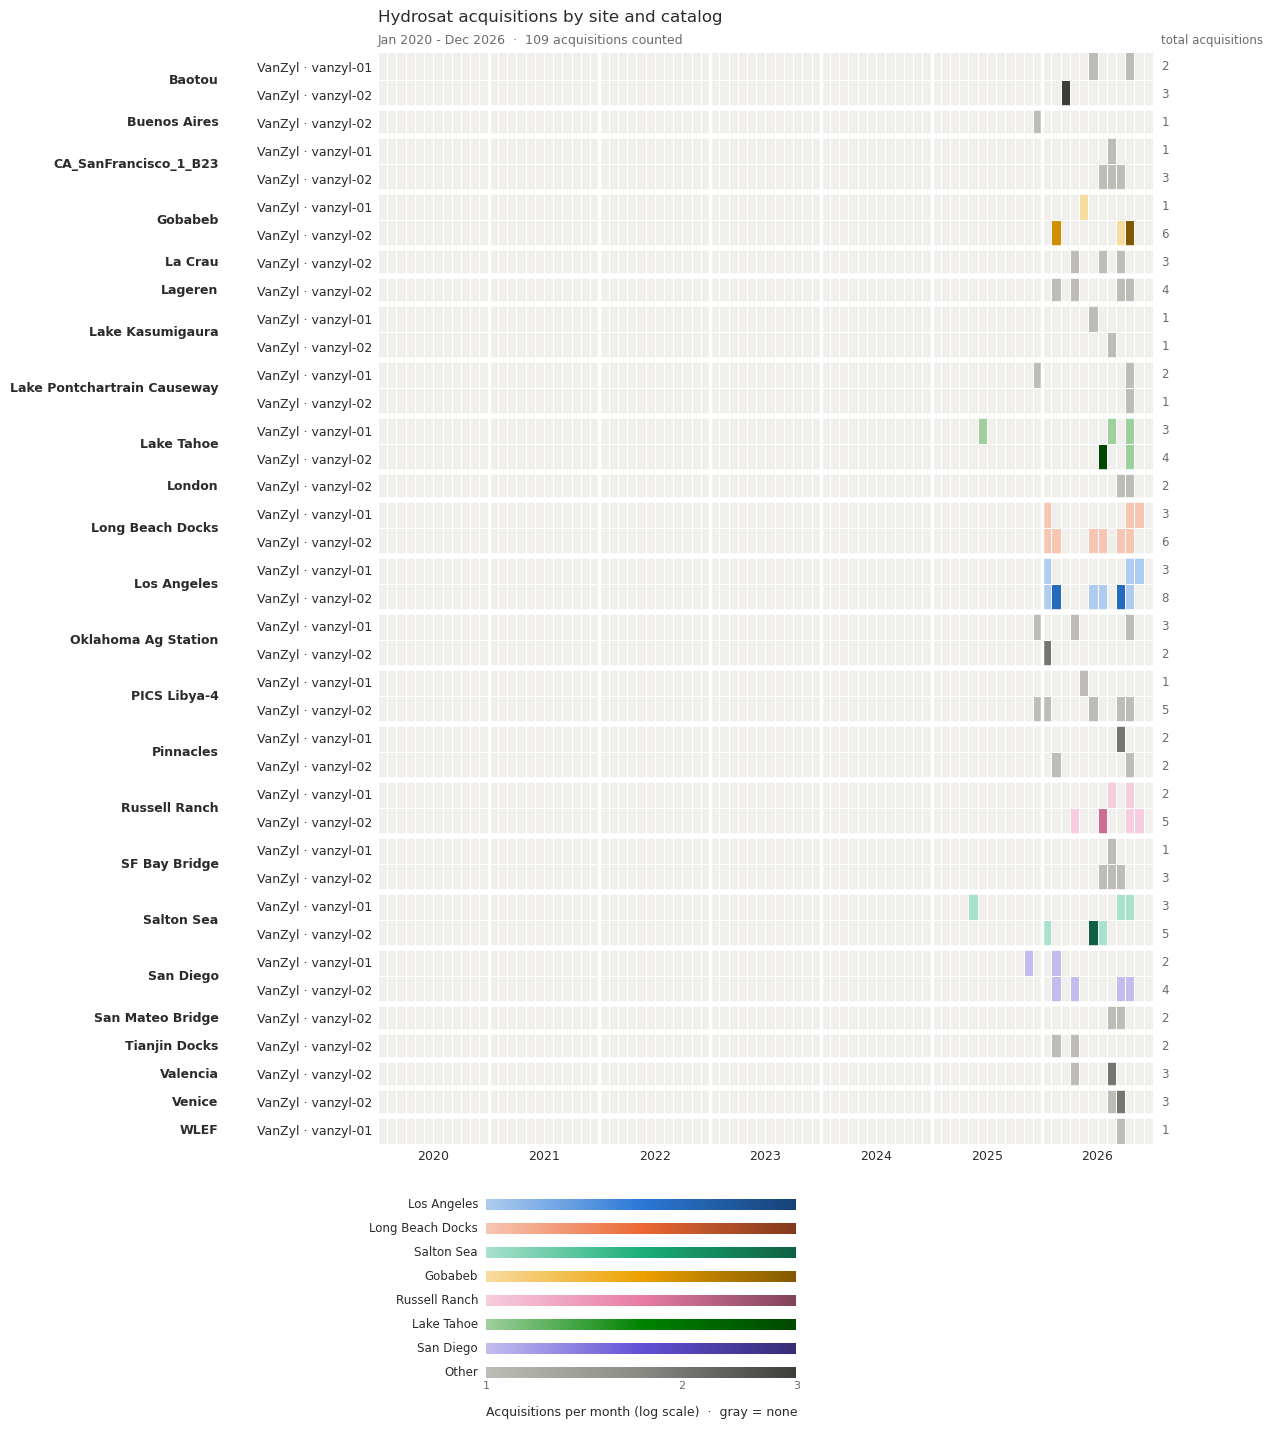

In [14]:
# Hydrosat acquisitions at the sites, by catalog: the L1B and L2 products of one scene count once
# (acquisition_id = hydrosat:scene_id). res.gdf keeps a row per site an item falls on, so per-site counts
# don't lose a scene that covers two nearby sites.
BY = ['site_name','constellation', 'platform']

multistac_plots.plot_month_heatmap(multistac.month_table(res.gdf, BY[0:2], count='acquisitions'), color_by='site_name', max_rows=None,
                                   start=START[:7], end=END[:7], title='Hydrosat acquisitions at the sites, by catalog');
multistac_plots.plot_month_heatmap(multistac.month_table(res.gdf, BY, count='acquisitions'), color_by='site_name', max_rows=None,
                                   start=START[:7], end=END[:7], title='Hydrosat acquisitions by site and catalog');


In [15]:
# Acquisitions per site in each catalog, and products per site by where they are available
display(res.gdf.groupby(['site_name', 'source_stac'])['acquisition_id'].nunique().unstack('source_stac', fill_value=0)
        .reindex(columns=list(SOURCE.values()), fill_value=0).sort_values(list(SOURCE.values()), ascending=False))
res.gdf.groupby(['site_name', 'available_from'])['id'].nunique().unstack('available_from', fill_value=0)


source_stac,CSDA STAC,Hydrosat API
site_name,,
Los Angeles,0,11
Long Beach Docks,0,9
Salton Sea,0,8
Gobabeb,0,7
Lake Tahoe,0,7
Russell Ranch,0,7
PICS Libya-4,0,6
San Diego,0,6
Baotou,0,5


available_from,Hydrosat API only
site_name,
Baotou,10
Buenos Aires,2
CA_SanFrancisco_1_B23,8
Gobabeb,14
La Crau,6
Lageren,8
Lake Kasumigaura,4
Lake Pontchartrain Causeway,6
Lake Tahoe,14


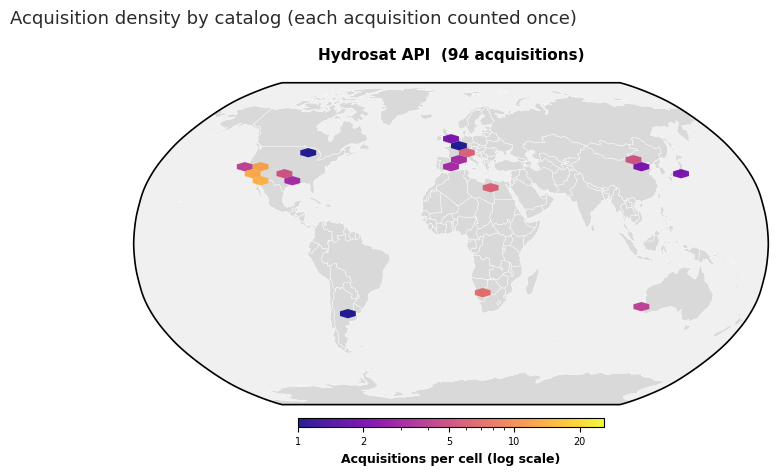

In [16]:
multistac_plots.plot_density_maps(gdf, facet_by=['source_stac'], max_facets=30, gridsize=40,
                                  count='acquisitions', title='Acquisition density by catalog (each acquisition counted once)');


## 4. Inherent variation: cloud, resolution, view and sun geometry

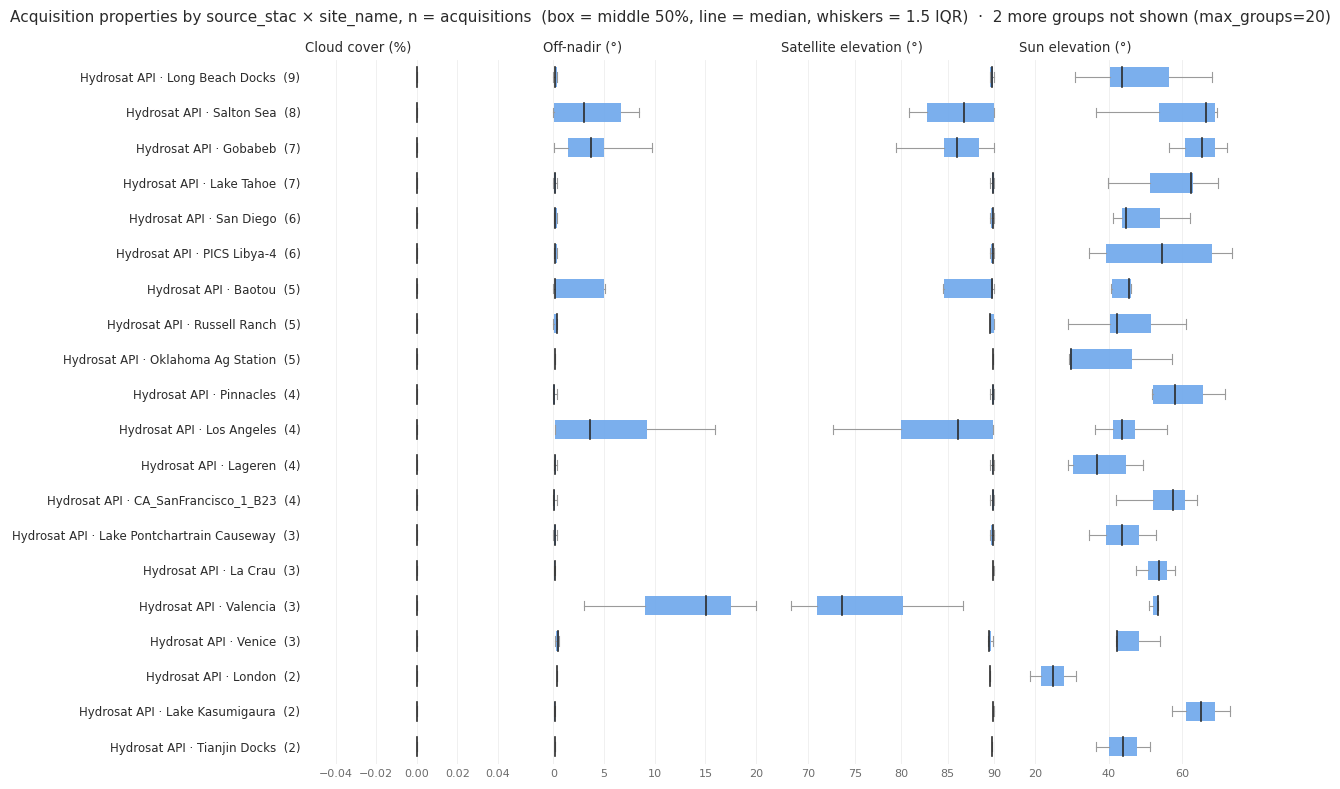

In [17]:
# Cloud cover and geometry of the products in each catalog
multistac_plots.plot_distributions(gdf, count='acquisitions', by=['source_stac', 'site_name']);


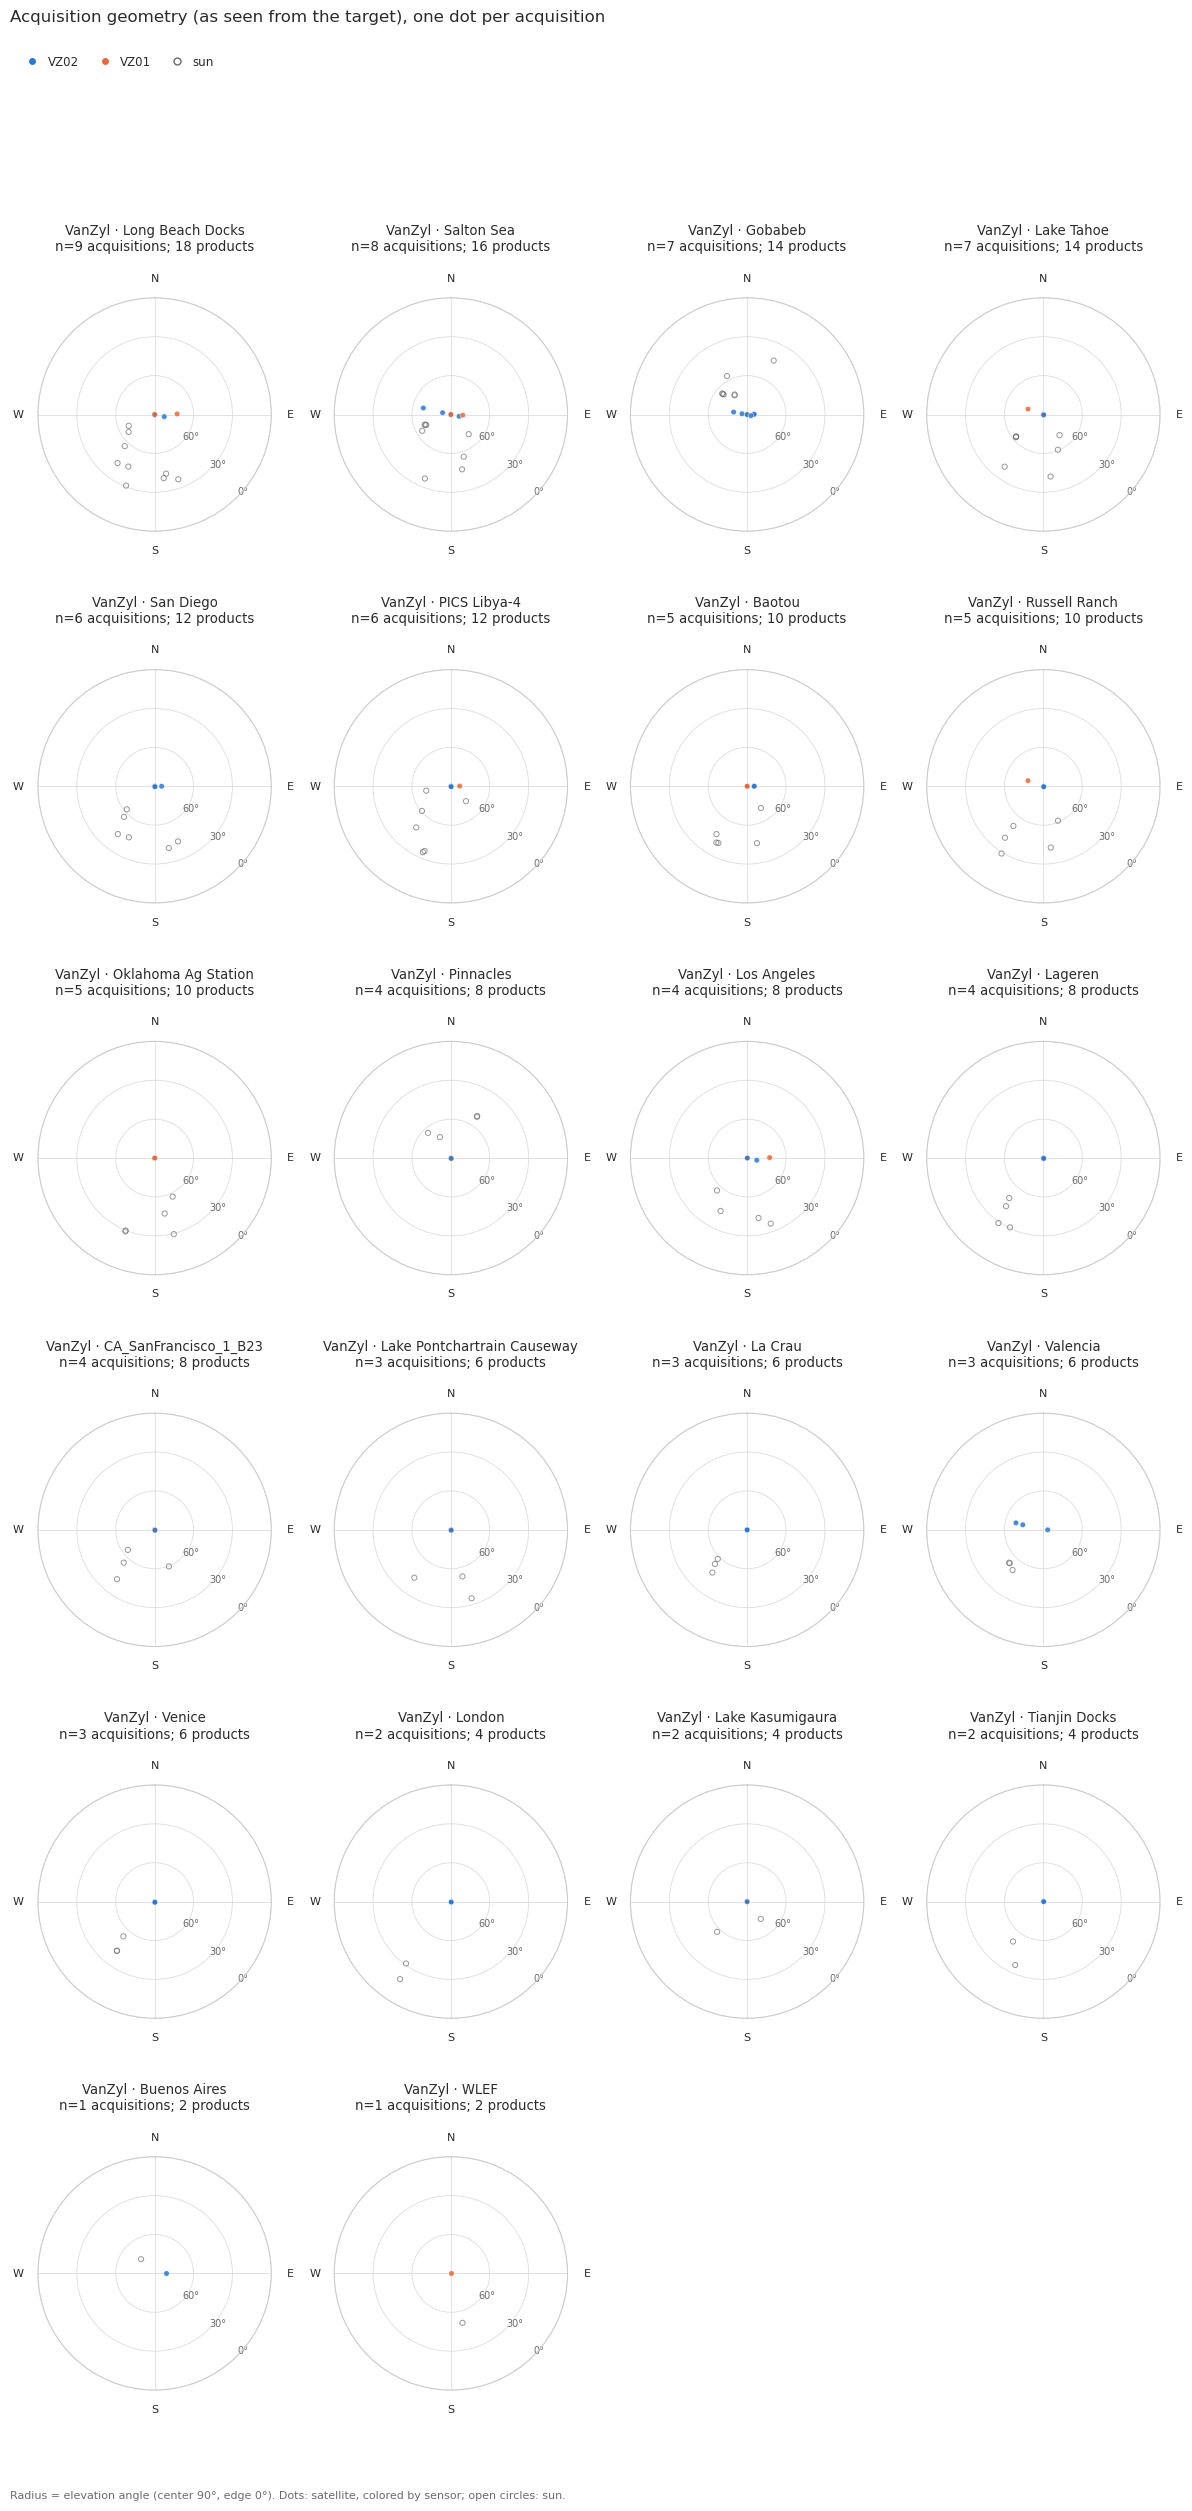

In [18]:
# Satellite and sun positions as seen from each site, one dot per acquisition (satellite colored by sensor).
# Rows without azimuths are left out; sat_elevation_source says when elevation is estimated.
if gdf[['sat_azimuth', 'sun_azimuth']].notna().all(axis=1).any():
    multistac_plots.plot_skyplot(gdf, facet_by=['constellation','site_group'], color_by='sensor', panel_size=3);
else:
    print('No rows with satellite and sun azimuths: no skyplot')


## 5. Download setup: Hydrosat data at CSDA STAC

Only products from the CSDA STAC rows are downloaded (Earthdata Login, `[EarthData]` in the multistac credentials file); the Hydrosat API has no download route here. The first cell only plans: it lists the assets and files and fetches nothing. Files go to `DOWNLOAD_DIR/csda/hydrosat/<item id>/`, existing files are skipped, and `download_manifest.csv` records what was fetched.

To download: set `DO_DOWNLOAD = True` in the parameters and run this section. Check the CSDA EULA first (each item's `csda:eula`).

In [19]:
# The plan: CSDA STAC products at the sites and their assets. Nothing is downloaded here.
to_get = res.gdf[res.gdf.provider == 'csda']
assets = multistac_download.list_assets(to_get)
display(assets)
wanted = DOWNLOAD_ASSETS or sorted(multistac_download.asset_table(to_get)['asset'].unique())
plan = multistac_download.download(to_get, DOWNLOAD_DIR, assets=wanted, dry_run=True)
print(f"{to_get.id.nunique()} products, {to_get.acquisition_id.nunique()} acquisitions at {to_get.site_name.nunique()} sites: "
      f"{len(plan)} files planned for {DOWNLOAD_DIR}")
if to_get.empty:
    print('CSDA STAC has no Hydrosat products at these sites yet. Re-run this notebook to check again.')
plan.groupby(['collection', 'status']).size()


,provider,collection,id,asset,roles,href,s3_href,filename


0 products, 0 acquisitions at 0 sites: 0 files planned for /explore/nobackup/projects/CSDA_eval/Data/Hydrosat
CSDA STAC has no Hydrosat products at these sites yet. Re-run this notebook to check again.


Series([], dtype: int64)

In [20]:
# Runs only with DO_DOWNLOAD = True
if DO_DOWNLOAD:
    manifest = multistac_download.download(to_get, DOWNLOAD_DIR, assets=wanted)
    display(manifest.groupby('status').agg(files=('id', 'size'), gigabytes=('bytes', lambda b: round(b.sum() / 1e9, 2))))
else:
    print(f'DO_DOWNLOAD is False: nothing downloaded. {len(plan)} files are planned.')


DO_DOWNLOAD is False: nothing downloaded. 0 files are planned.


## Publish to the dashboard

Updates this vendor's tab in `html/archive_first_look.html`, the page for the SMEs: good acquisitions by site and sensor, with the limits set on the page. It runs its own search with no cloud limit so the SMEs can change them, and leaves the results above alone. Commit and push the page and `html/archive_first_look_data/` to publish.

In [21]:
import archive_dashboard
importlib.reload(archive_dashboard)
dash = multistac.search(sites, START, END, {**PROVIDERS, 'hydrosat': PROVIDERS['hydrosat'] + ['vz-l1b-night']})   # no cloud limit, no cache; adds night scenes
print(dash)
archive_dashboard.publish('hydrosat', dash.gdf, sites, SITES, SITE_NAME_FIELD, START, END, dash.log)

searches: 100%|██████████| 116/116 [00:08<00:00, 13.29it/s]


SearchResult(684 rows, 616 unique items, 0 failed tasks)
Hydrosat VanZyl: 357 acquisition-site rows, 616 catalog items, 29 sites
/panfs/ccds02/home/pmontesa/code/csda_summaries/html/archive_first_look.html


PosixPath('/panfs/ccds02/home/pmontesa/code/csda_summaries/html/archive_first_look.html')